In [121]:
import os
import kagglehub
import pandas as pd


# 1. Download and locate the dataset file
path = kagglehub.dataset_download("hopesb/student-depression-dataset")
csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))

# 2. Structural Inspection
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
display(df.head())
print("\n--- Data Types & Non-Null Counts ---")
df.info()

Dataset Shape: 27901 rows, 18 columns



,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0



--- Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   Gender                                 27901 non-null  str    
 2   Age                                    27901 non-null  float64
 3   City                                   27901 non-null  str    
 4   Profession                             27901 non-null  str    
 5   Academic Pressure                      27901 non-null  float64
 6   Work Pressure                          27901 non-null  float64
 7   CGPA                                   27901 non-null  float64
 8   Study Satisfaction                     27901 non-null  float64
 9   Job Satisfaction                       27901 non-null  float64
 10  Sleep Duration                         2790

In [122]:
df.drop('id', axis=1, inplace=True)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16028\48924119.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('id', axis=1, inplace=True)


In [123]:
# Check for exact duplicate rows
print(f"Total Duplicate Rows: {df.duplicated().sum()}\n")

# Check for missing values (count and percentage)
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage (%)': missing_pct})
print("--- Missing Values ---")
print(missing_df[missing_df['Missing Count'] > 0], "\n")

# Summary statistics for numerical columns (helps spot impossible values/outliers)
print("--- Numerical Summary ---")
display(df.describe())

# Check unique values in categorical/object columns (helps spot typos or inconsistencies)
print("\n--- Categorical Unique Values ---")
for col in df.select_dtypes(include='object').columns:
    print(f"{col} ({df[col].nunique()} unique): {df[col].unique()}")
    print("\n\n")

Total Duplicate Rows: 0

--- Missing Values ---
                  Missing Count  Percentage (%)
Financial Stress              3        0.010752 

--- Numerical Summary ---


,Age,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Work/Study Hours,Financial Stress,Depression
count,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27898.000000,27901.000000
mean,25.822300,3.141214,0.000430,7.656104,2.943837,0.000681,7.156984,3.139867,0.585499
std,4.905687,1.381465,0.043992,1.470707,1.361148,0.044394,3.707642,1.437347,0.492645
min,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,21.000000,2.000000,0.000000,6.290000,2.000000,0.000000,4.000000,2.000000,0.000000
50%,25.000000,3.000000,0.000000,7.770000,3.000000,0.000000,8.000000,3.000000,1.000000
75%,30.000000,4.000000,0.000000,8.920000,4.000000,0.000000,10.000000,4.000000,1.000000
max,59.000000,5.000000,5.000000,10.000000,5.000000,4.000000,12.000000,5.000000,1.000000



--- Categorical Unique Values ---
Gender (2 unique): <StringArray>
['Male', 'Female']
Length: 2, dtype: str



City (52 unique): <StringArray>
[     'Visakhapatnam',          'Bangalore',           'Srinagar',
           'Varanasi',             'Jaipur',               'Pune',
              'Thane',            'Chennai',             'Nagpur',
             'Nashik',           'Vadodara',             'Kalyan',
             'Rajkot',          'Ahmedabad',            'Kolkata',
             'Mumbai',            'Lucknow',             'Indore',
              'Surat',           'Ludhiana',             'Bhopal',
             'Meerut',               'Agra',          'Ghaziabad',
          'Hyderabad',        'Vasai-Virar',             'Kanpur',
              'Patna',          'Faridabad',              'Delhi',
             'Saanvi',             'M.Tech',             'Bhavna',
         'Less Delhi',               'City',                '3.0',
 'Less than 5 Kalyan',               'Mira',        

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16028\1111692082.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [124]:
# 1. Count how many rows are NOT 'Student'
non_student_count = (df['Profession'] != 'Student').sum()
print(f"Number of rows where Profession != 'Student': {non_student_count}")

# 2. See what those specific values are (e.g., Teacher, Engineer, etc.)
print("\nBreakdown of non-student professions:")
print(df[df['Profession'] != 'Student']['Profession'].value_counts())

Number of rows where Profession != 'Student': 31

Breakdown of non-student professions:
Profession
Architect                 8
Teacher                   6
Digital Marketer          3
Content Writer            2
Chef                      2
Doctor                    2
Pharmacist                2
Civil Engineer            1
UX/UI Designer            1
Educational Consultant    1
Manager                   1
Lawyer                    1
Entrepreneur              1
Name: count, dtype: int64


In [125]:
## Keep only 'Student' rows, then drop the column since it now has zero variance
df = df[df['Profession'].str.strip().str.lower() == 'student'].drop(columns=['Profession'])

In [126]:
#Missing Value Treatement
# 1. Inspect the 3 rows with missing Financial Stress before fixing
print("Rows with missing Financial Stress:")
display(df[df['Financial Stress'].isnull()])

# 2. Ensure the column is numeric and calculate the median
df['Financial Stress'] = pd.to_numeric(df['Financial Stress'], errors='coerce')
median_stress = df['Financial Stress'].median()

# 3. Fill the missing values with the median
df['Financial Stress'] = df['Financial Stress'].fillna(median_stress)

# 4. Verify the fix
print(f"\nImputed with median value: {median_stress}")
print(f"Remaining missing values in Financial Stress: {df['Financial Stress'].isnull().sum()}")

Rows with missing Financial Stress:


,Gender,Age,City,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
4458,Female,32.0,Varanasi,3.0,0.0,5.64,1.0,0.0,5-6 hours,Healthy,BCA,No,12.0,NaN,No,1
13596,Male,29.0,Hyderabad,2.0,0.0,8.94,3.0,0.0,Less than 5 hours,Unhealthy,B.Ed,No,12.0,NaN,Yes,0
19266,Female,20.0,Kolkata,1.0,0.0,6.83,1.0,0.0,5-6 hours,Healthy,MBBS,No,9.0,NaN,Yes,0



Imputed with median value: 3.0
Remaining missing values in Financial Stress: 0


In [127]:
other_sleepduration_count = (df['Sleep Duration'] != 'Others').sum()
print(f"Number of rows where Sleep Duration == 'Others': {non_student_count}")
other_sleepduration_count = (df['Dietary Habits'] != 'Others').sum()
print(f"Number of rows where Dietary Habits == 'Others': {non_student_count}")

Number of rows where Sleep Duration == 'Others': 31
Number of rows where Dietary Habits == 'Others': 31


In [128]:
# Remove ambiguous 'Others' in Sleep Duration and Dietary Habits (usually < 50 rows total)
df = df[df['Sleep Duration'] != 'Others']
df = df[df['Dietary Habits'] != 'Others']

In [129]:
# Group rare/typo categories in 'City' and 'Degree' (e.g., entries appearing < 10 times)
for col in ['City', 'Degree']:
    if col in df.columns:
        value_counts = df[col].value_counts()
        rare_labels = value_counts[value_counts < 10].index
        df[col] = df[col].replace(rare_labels, 'Other')
        print(f"Grouped {len(rare_labels)} rare/noisy labels in '{col}' into 'Other'")

Grouped 22 rare/noisy labels in 'City' into 'Other'
Grouped 0 rare/noisy labels in 'Degree' into 'Other'


In [130]:
import numpy as np
# Domain Check 1: Enforce valid CGPA range [0, 10] first
invalid_cgpa_range = df[(df['CGPA'] < 0) | (df['CGPA'] > 10)]
print(f"Out-of-range CGPA rows (< 0 or > 10) removed: {len(invalid_cgpa_range)}")
df = df[(df['CGPA'] >= 0) & (df['CGPA'] <= 10)]

# Domain Check 2: Impute 0.0 CGPA entries with the median of valid (> 0) CGPAs
zero_cgpa_count = (df['CGPA'] == 0).sum()
if zero_cgpa_count > 0:
    valid_cgpa_median = df[df['CGPA'] > 0]['CGPA'].median()
    df.loc[df['CGPA'] == 0, 'CGPA'] = valid_cgpa_median
    print(f"Replaced {zero_cgpa_count} invalid 0.0 CGPA entries with median: {valid_cgpa_median:.2f}")

# Domain Check 3: Ensure Work/Study Hours are within [0, 24] and Age is realistic for students
df = df[(df['Work/Study Hours'] >= 0) & (df['Work/Study Hours'] <= 24)]
df = df[(df['Age'] >= 15) & (df['Age'] <= 60)]

# Statistical Outlier Check (IQR Method) for continuous features ('Age', 'CGPA')
for col in ['Age', 'CGPA']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (df[col] < lower_bound) | (df[col] > upper_bound)
    print(
        f"IQR outliers detected in '{col}': {outlier_mask.sum()} rows "
        f"(Bounds: {lower_bound:.2f} to {upper_bound:.2f})"
    )

    # Remove detected outliers
    df = df.loc[~outlier_mask].copy()

Out-of-range CGPA rows (< 0 or > 10) removed: 0
Replaced 9 invalid 0.0 CGPA entries with median: 7.77
IQR outliers detected in 'Age': 12 rows (Bounds: 7.50 to 43.50)
IQR outliers detected in 'CGPA': 0 rows (Bounds: 2.35 to 12.87)


In [131]:
# FINAL VERIFICATION AUDIT

print("\n--- Post-Cleaning Verification ---")
print(f"Final Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Remaining Missing Values: {df.isnull().sum().sum()}")
print(f"Remaining Duplicates: {df.duplicated().sum()}")


--- Post-Cleaning Verification ---
Final Shape: 27828 rows, 16 columns
Remaining Missing Values: 0
Remaining Duplicates: 0


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16028\2138883022.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Depression', palette=['#4C72B0', '#DD8452'])


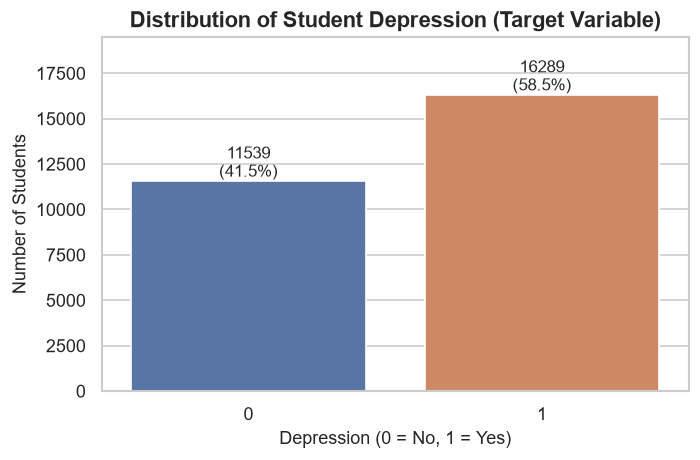

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16028\2138883022.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Depression', y=col, ax=axes[i], palette=['#4C72B0', '#DD8452'])
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16028\2138883022.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Depression', y=col, ax=axes[i], palette=['#4C72B0', '#DD8452'])
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16028\2138883022.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Depression', y=col, ax=axes[i], palett

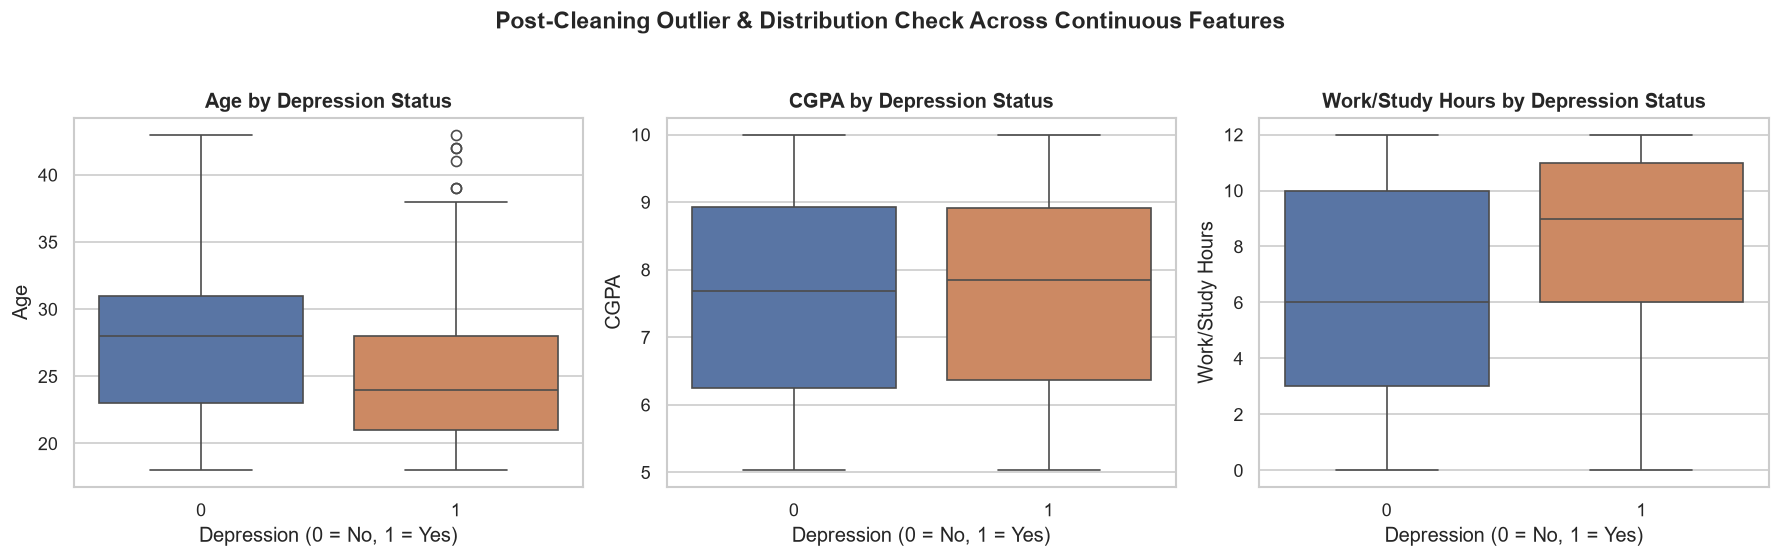

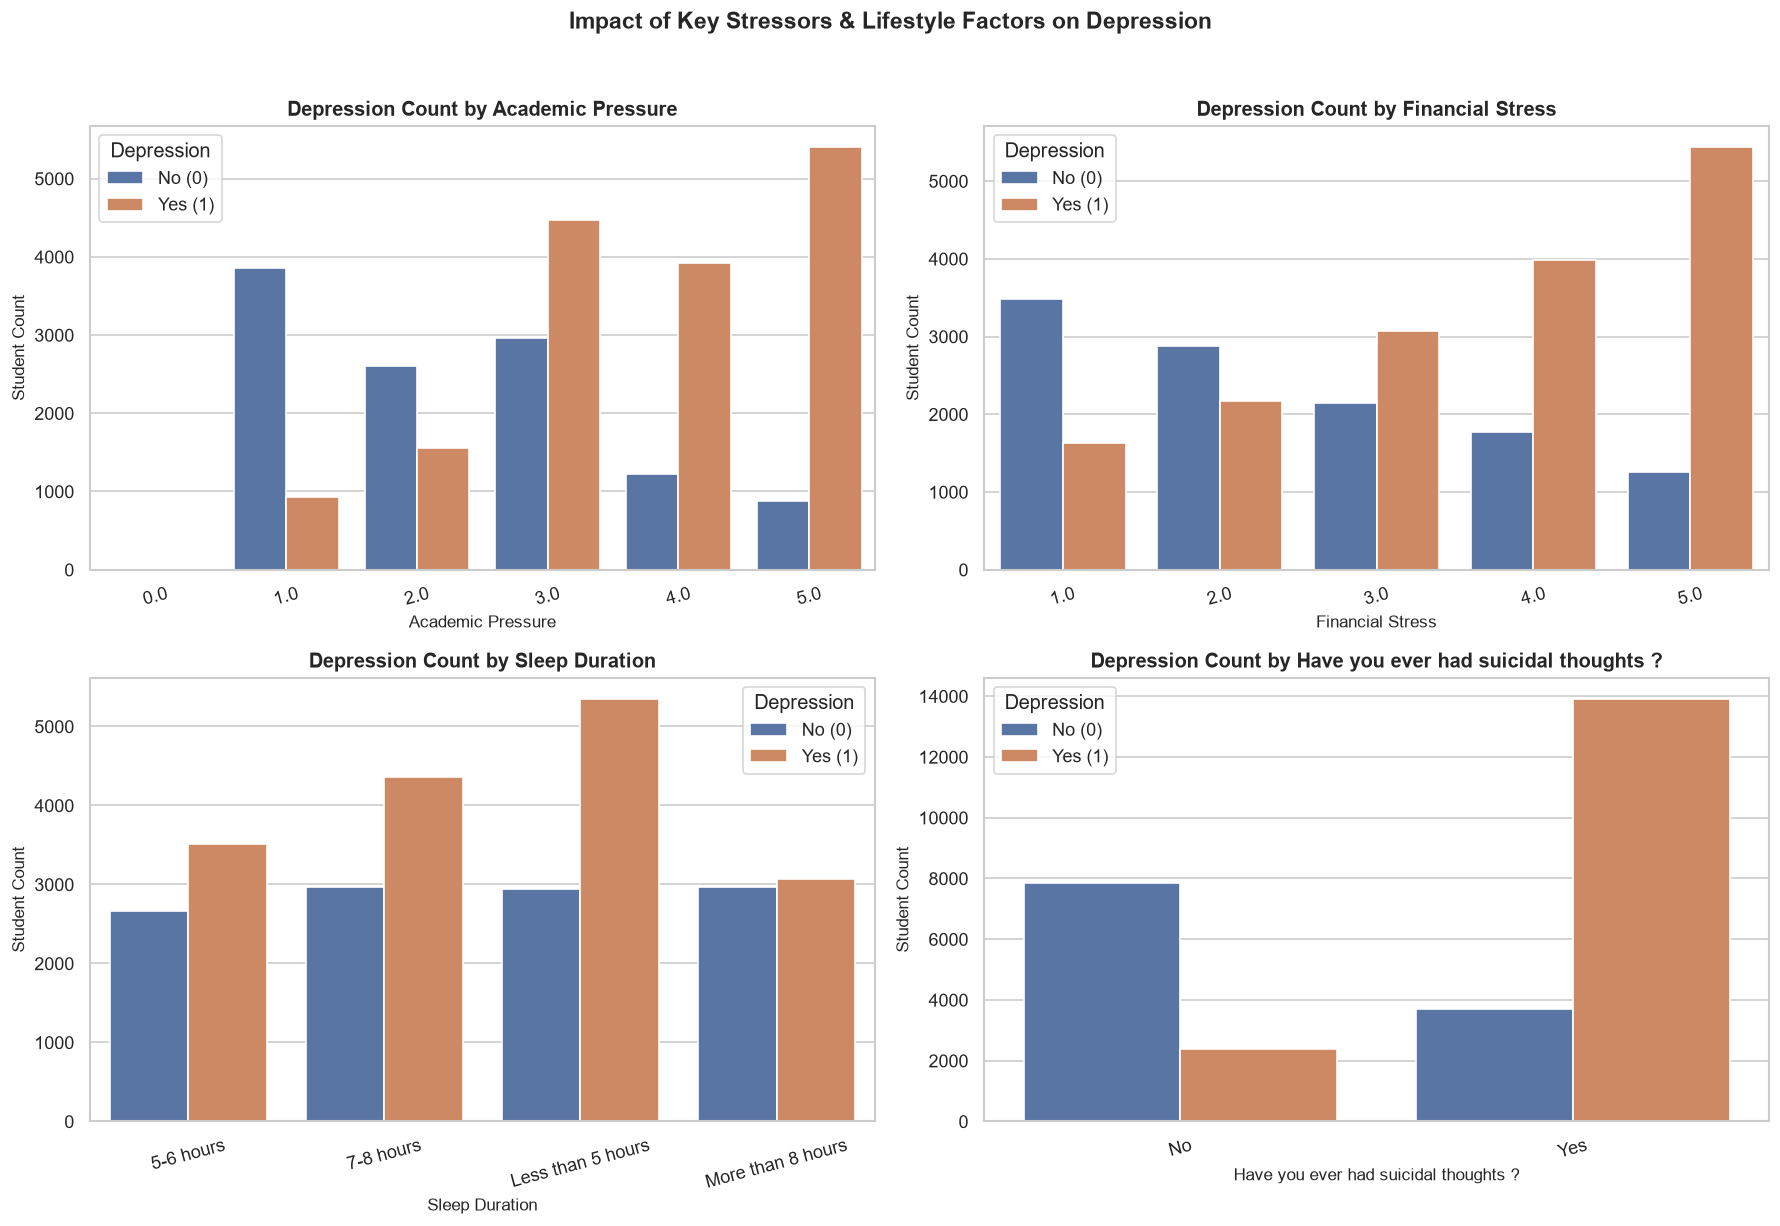

In [132]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set a clean, academic visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120

# ---------------------------------------------------------
# 1. TARGET VARIABLE DISTRIBUTION (Class Balance Check)
# ---------------------------------------------------------
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='Depression', palette=['#4C72B0', '#DD8452'])
plt.title('Distribution of Student Depression (Target Variable)', fontsize=13, fontweight='bold')
plt.xlabel('Depression (0 = No, 1 = Yes)', fontsize=11)
plt.ylabel('Number of Students', fontsize=11)

# Add percentage annotations on top of bars
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(f'{int(y)}\n({percentage})', (x, y), ha='center', va='bottom', fontsize=10)

plt.ylim(0, total * 0.7)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. BOXPLOTS FOR OUTLIER & RANGE VERIFICATION
# ---------------------------------------------------------
num_cols = ['Age', 'CGPA', 'Work/Study Hours']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x='Depression', y=col, ax=axes[i], palette=['#4C72B0', '#DD8452'])
    axes[i].set_title(f'{col} by Depression Status', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Depression (0 = No, 1 = Yes)')
    axes[i].set_ylabel(col)

plt.suptitle('Post-Cleaning Outlier & Distribution Check Across Continuous Features', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. KEY CATEGORICAL & ORDINAL DRIVERS VS. DEPRESSION
# ---------------------------------------------------------
cat_cols = ['Academic Pressure', 'Financial Stress', 'Sleep Duration', 'Have you ever had suicidal thoughts ?']
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    # Sort order cleanly for ordinal columns
    order = sorted(df[col].unique()) if df[col].dtype != 'object' else None
    sns.countplot(data=df, x=col, hue='Depression', order=order, ax=axes[i], palette=['#4C72B0', '#DD8452'])
    axes[i].set_title(f'Depression Count by {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Student Count', fontsize=10)
    axes[i].legend(title='Depression', labels=['No (0)', 'Yes (1)'])
    axes[i].tick_params(axis='x', rotation=15)

plt.suptitle('Impact of Key Stressors & Lifestyle Factors on Depression', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

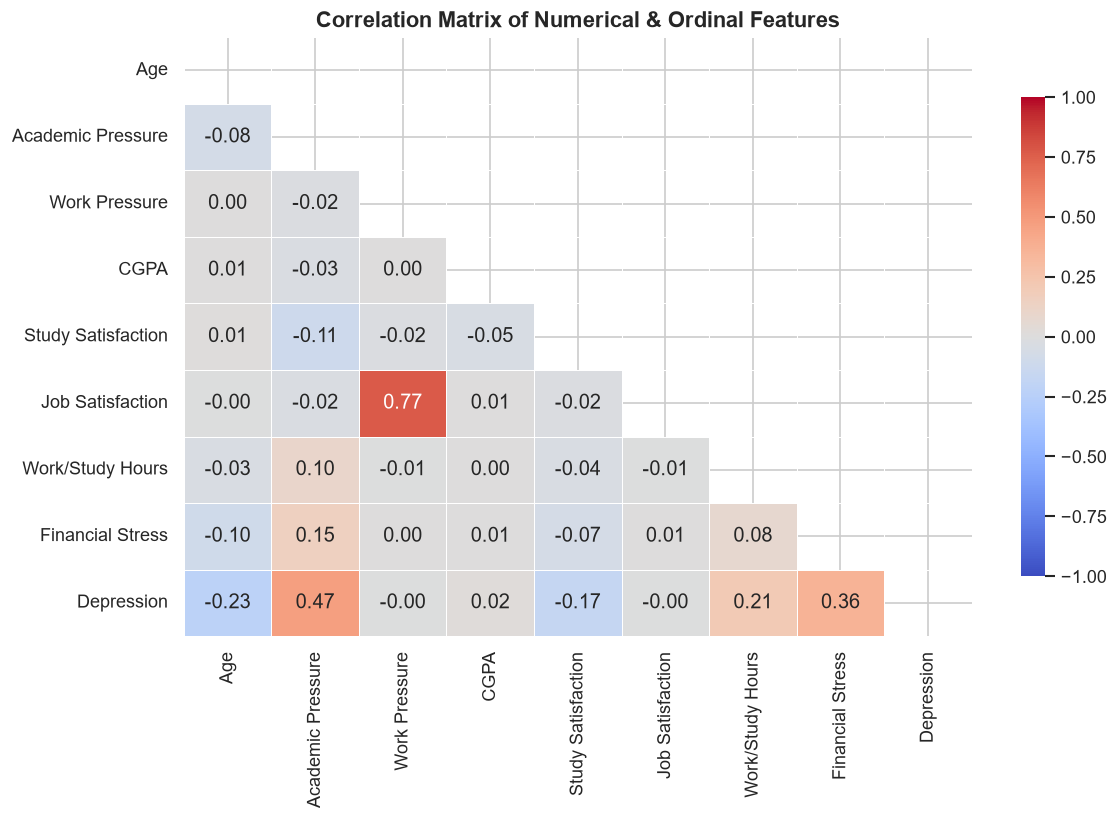

In [133]:

# NUMERICAL CORRELATION HEATMAP
plt.figure(figsize=(10, 7))
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

# Mask the upper triangle to avoid redundant mirrored values
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)
plt.title('Correlation Matrix of Numerical & Ordinal Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [134]:

import pandas as pd
import numpy as np
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

# ---------------------------------------------------------
# 1. DEFINE TARGET VARIABLE & DROP NON-INFORMATIVE COLUMNS
# ---------------------------------------------------------
target = 'Depression'

# Drop columns proven redundant/near-constant from Task 1 & Heatmap
cols_to_drop = ['Work Pressure', 'Job Satisfaction']
df_model = df.drop(columns=[c for c in cols_to_drop if c in df.columns]).copy()

# ---------------------------------------------------------
# 2. ENCODE CATEGORICAL FEATURES
# ---------------------------------------------------------
# Binary / Ordinal Mappings (preserves natural order)
binary_map = {'Yes': 1, 'No': 0}
df_model['Have you ever had suicidal thoughts ?'] = df_model['Have you ever had suicidal thoughts ?'].map(binary_map)
df_model['Family History of Mental Illness'] = df_model['Family History of Mental Illness'].map(binary_map)

sleep_map = {
    'Less than 5 hours': 1,
    '5-6 hours': 2,
    '7-8 hours': 3,
    'More than 8 hours': 4
}
df_model['Sleep Duration'] = df_model['Sleep Duration'].map(sleep_map)

diet_map = {'Unhealthy': 1, 'Moderate': 2, 'Healthy': 3}
df_model['Dietary Habits'] = df_model['Dietary Habits'].map(diet_map)

# One-Hot Encode remaining nominal categorical columns (Gender, Degree, City)
X = df_model.drop(columns=[target])
y = df_model[target]
X_encoded = pd.get_dummies(X, drop_first=True)

# ---------------------------------------------------------
# 3. QUANTITATIVE FEATURE RELEVANCE RANKING
# ---------------------------------------------------------
# Method A: Mutual Information (captures non-linear relationships)
mi_scores = mutual_info_classif(X_encoded, y, random_state=42)

# Method B: Random Forest Feature Importance (tree-based split contribution)
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_encoded, y)
rf_scores = rf.feature_importances_

# Combine into a comparison table
feature_ranking = pd.DataFrame({
    'Feature': X_encoded.columns,
    'Mutual_Info': mi_scores,
    'RF_Importance': rf_scores
}).sort_values(by='RF_Importance', ascending=False)

print("--- Top 15 Most Relevant Features ---")
display(feature_ranking.head(15))

print("\n--- Bottom 10 Least Relevant Features (Candidates to Drop) ---")
display(feature_ranking.tail(10))

--- Top 15 Most Relevant Features ---


,Feature,Mutual_Info,RF_Importance
6,Have you ever had suicidal thoughts ?,0.156090,0.196089
1,Academic Pressure,0.125575,0.156720
8,Financial Stress,0.071731,0.090893
0,Age,0.031858,0.073030
2,CGPA,0.002888,0.069377
7,Work/Study Hours,0.023271,0.064079
3,Study Satisfaction,0.013267,0.039435
5,Dietary Habits,0.019545,0.035592
4,Sleep Duration,0.000000,0.029202
10,Gender_Male,0.008232,0.014935



--- Bottom 10 Least Relevant Features (Candidates to Drop) ---


,Feature,Mutual_Info,RF_Importance
53,Degree_LLM,0.001669,0.002942
59,Degree_MBA,0.000000,0.002941
62,Degree_MD,0.000000,0.002905
67,Degree_PhD,0.000000,0.002848
29,City_Nashik,0.000000,0.002813
16,City_Faridabad,0.000000,0.002708
64,Degree_MHM,0.000000,0.001526
63,Degree_ME,0.005634,0.001515
66,Degree_Others,0.003575,0.000440
30,City_Other,0.001189,0.000194


In [135]:
%pip insall jinja2

Note: you may need to restart the kernel to use updated packages.


ERROR: unknown command "insall" - maybe you meant "install"



Training samples: 22262 | Testing samples: 5566


c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


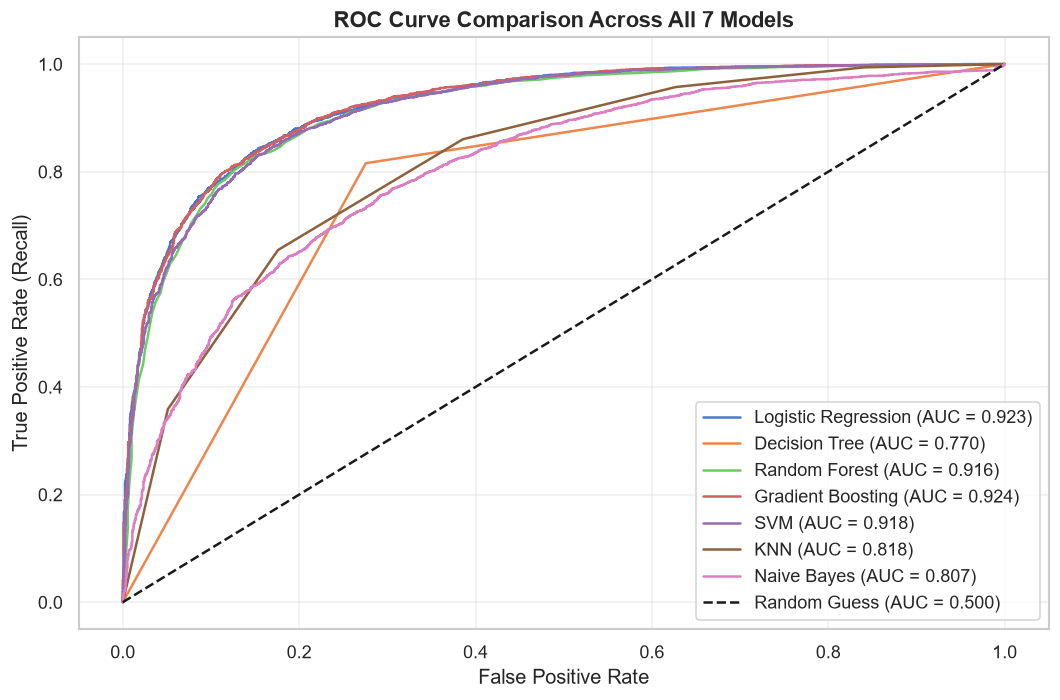


--- Model Performance Comparison (Ranked by F1-Score) ---


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,0.8476,0.8571,0.8877,0.8721,0.9236
1,Logistic Regression,0.8478,0.8593,0.8849,0.8719,0.9234
2,Random Forest,0.8423,0.8521,0.8840,0.8677,0.9157
3,SVM,0.8419,0.8532,0.8815,0.8671,0.9177
4,Decision Tree,0.7779,0.8069,0.8158,0.8114,0.7701
5,KNN,0.7584,0.7590,0.8603,0.8065,0.8179
6,Naive Bayes,0.7361,0.7810,0.7630,0.7719,0.8065


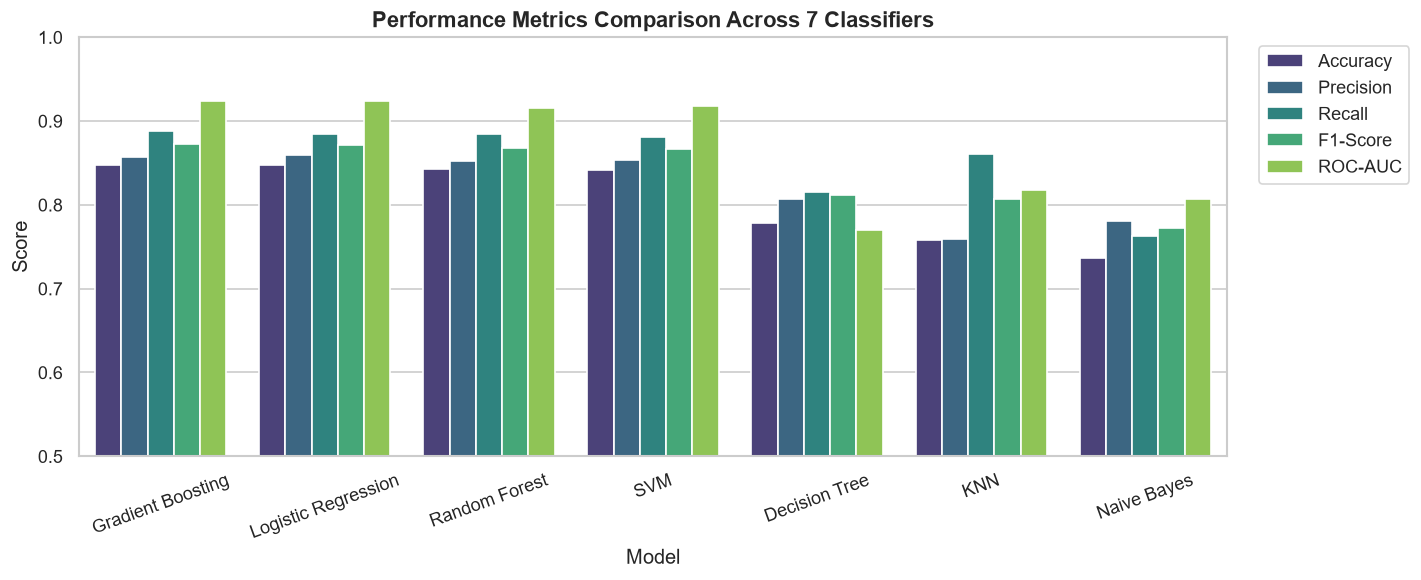


Best Performing Individual Model: Gradient Boosting
              precision    recall  f1-score   support

           0       0.83      0.79      0.81      2308
           1       0.86      0.89      0.87      3258

    accuracy                           0.85      5566
   macro avg       0.85      0.84      0.84      5566
weighted avg       0.85      0.85      0.85      5566



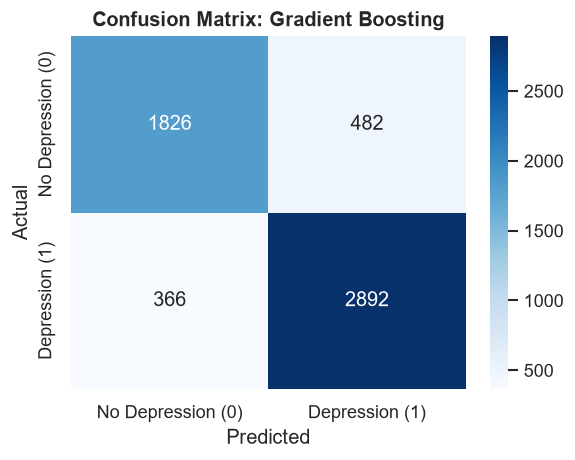

In [136]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Your 7 selected models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

# ---------------------------------------------------------
# 1. TRAIN-TEST SPLIT (80% Train, 20% Test, Stratified)
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training samples: {X_train.shape[0]} | Testing samples: {X_test.shape[0]}")

# ---------------------------------------------------------
# 2. DEFINE ALL 7 MODELS (Using Pipelines for Scaling)
# ---------------------------------------------------------
# StandardScaler is fitted ONLY on X_train inside the pipeline to prevent data leakage
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC(probability=True, random_state=42)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Naive Bayes": make_pipeline(StandardScaler(), GaussianNB())
}

# ---------------------------------------------------------
# 3. TRAIN, PREDICT & EVALUATE ALL MODELS
# ---------------------------------------------------------
results = []
trained_models = {}

plt.figure(figsize=(9, 6))

for name, model in models.items():
    # Train
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    # Predict class labels & probabilities
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc
    })
    
    # Plot ROC Curve for each model
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

# Finalize ROC Curve Plot
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess (AUC = 0.500)")
plt.title("ROC Curve Comparison Across All 7 Models", fontsize=13, fontweight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 4. DISPLAY RANKED COMPARISON TABLE & BAR CHART
# ---------------------------------------------------------
results_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
print("\n--- Model Performance Comparison (Ranked by F1-Score) ---")
display(results_df.round(4))

# Visual Bar Chart Comparison
results_melted = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 5))
sns.barplot(data=results_melted, x="Model", y="Score", hue="Metric", palette="viridis")
plt.title("Performance Metrics Comparison Across 7 Classifiers", fontsize=13, fontweight="bold")
plt.ylim(0.5, 1.0)
plt.xticks(rotation=20)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Inspect Best Model Details (Confusion Matrix)
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
y_pred_best = best_model.predict(X_test)

# ---------------------------------------------------------
# 5. INSPECT BEST MODEL DETAILS (Confusion Matrix)
# ---------------------------------------------------------
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
y_pred_best = best_model.predict(X_test)

print(f"\nBest Performing Individual Model: {best_model_name}")
print(classification_report(y_test, y_pred_best))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_best), annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Depression (0)", "Depression (1)"],
            yticklabels=["No Depression (0)", "Depression (1)"])
plt.title(f"Confusion Matrix: {best_model_name}", fontweight="bold")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()

--- Meta-Classifier vs. Top 3 Individual Base Models ---


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Stacking Meta-Classifier,0.8475,0.8590,0.8846,0.8716,0.9240
1,Gradient Boosting,0.8476,0.8571,0.8877,0.8721,0.9236
2,Logistic Regression,0.8478,0.8593,0.8849,0.8719,0.9234
3,Random Forest,0.8423,0.8521,0.8840,0.8677,0.9157



--- Meta-Classifier Learned Weights ---


,Base Model,Meta-Learner Coefficient (Weight)
0,Gradient Boosting,2.2477
1,Logistic Regression,2.6898
2,Random Forest,1.2924


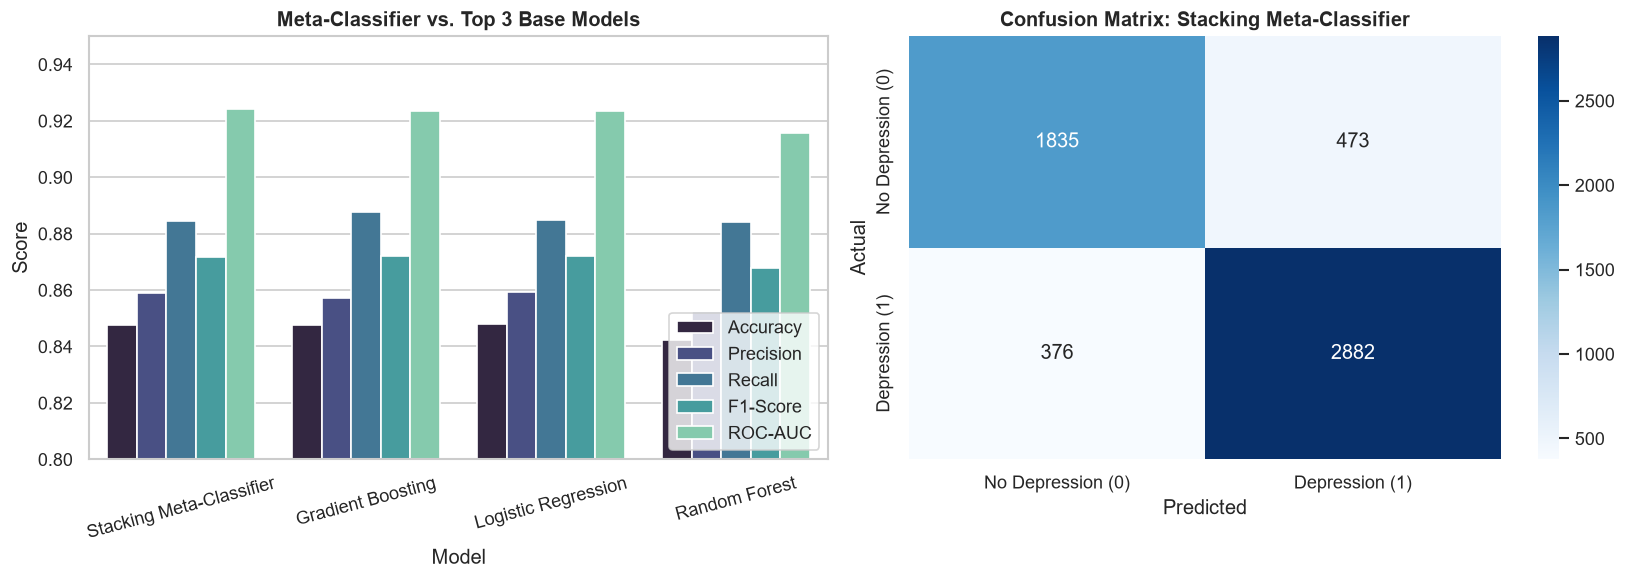

In [137]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import StackingClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ---------------------------------------------------------
# 1. DEFINE THE TOP 3 BASE MODELS (LEVEL-0 ESTIMATORS)
# ---------------------------------------------------------
base_estimators = [
    ('gb', GradientBoostingClassifier(random_state=42)),
    ('lr', make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42))
]

# ---------------------------------------------------------
# 2. DEFINE & TRAIN THE STACKING META-CLASSIFIER (LEVEL-1)
# ---------------------------------------------------------
# Uses 5-fold cross-validation to generate out-of-fold predicted probabilities
# Final meta-learner (Logistic Regression) learns optimal weights to combine them
meta_classifier = StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(random_state=42),
    cv=5,
    stack_method='predict_proba',
    n_jobs=-1
)

meta_classifier.fit(X_train, y_train)

# ---------------------------------------------------------
# 3. EVALUATE META-CLASSIFIER ON TEST SET
# ---------------------------------------------------------
y_pred_meta = meta_classifier.predict(X_test)
y_prob_meta = meta_classifier.predict_proba(X_test)[:, 1]

meta_metrics = {
    "Model": "Stacking Meta-Classifier",
    "Accuracy": accuracy_score(y_test, y_pred_meta),
    "Precision": precision_score(y_test, y_pred_meta),
    "Recall": recall_score(y_test, y_pred_meta),
    "F1-Score": f1_score(y_test, y_pred_meta),
    "ROC-AUC": roc_auc_score(y_test, y_prob_meta)
}

# ---------------------------------------------------------
# 4. COMPARE META-CLASSIFIER VS. TOP 3 BASE MODELS
# ---------------------------------------------------------
top3_df = results_df[results_df['Model'].isin([
    'Gradient Boosting', 'Logistic Regression', 'Random Forest'
])].copy()

comparison_df = pd.concat([pd.DataFrame([meta_metrics]), top3_df], ignore_index=True)
print("--- Meta-Classifier vs. Top 3 Individual Base Models ---")
display(comparison_df.round(4))

# Inspect Meta-Learner Weights (Shows how much each base model contributed!)
meta_weights = pd.DataFrame({
    'Base Model': ['Gradient Boosting', 'Logistic Regression', 'Random Forest'],
    'Meta-Learner Coefficient (Weight)': meta_classifier.final_estimator_.coef_[0]
})
print("\n--- Meta-Classifier Learned Weights ---")
display(meta_weights.round(4))

# ---------------------------------------------------------
# 5. VISUALIZE PERFORMANCE & CONFUSION MATRIX
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Metric Comparison Bar Chart
melted_comp = comparison_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    var_name="Metric",
    value_name="Score"
)
sns.barplot(data=melted_comp, x="Model", y="Score", hue="Metric", ax=axes[0], palette="mako")
axes[0].set_title("Meta-Classifier vs. Top 3 Base Models", fontweight="bold")
axes[0].set_ylim(0.80, 0.95)
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(loc="lower right")

# Plot 2: Confusion Matrix for Meta-Classifier
sns.heatmap(
    confusion_matrix(y_test, y_pred_meta),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1],
    xticklabels=["No Depression (0)", "Depression (1)"],
    yticklabels=["No Depression (0)", "Depression (1)"]
)
axes[1].set_title("Confusion Matrix: Stacking Meta-Classifier", fontweight="bold")
axes[1].set_ylabel("Actual")
axes[1].set_xlabel("Predicted")

plt.tight_layout()
plt.show()

In [142]:
import pandas as pd

def predict_student_depression(sample_dict, model, training_columns):
    """
    Takes a raw dictionary of student attributes, applies the exact
    preprocessing/encoding pipeline used during training, and predicts depression.
    """
    # 1. Convert raw input dictionary into a 1-row DataFrame
    input_df = pd.DataFrame([sample_dict])
    
    # 2. Apply the exact ordinal/binary mappings from Task 2
    binary_map = {'Yes': 1, 'No': 0}
    sleep_map = {
        'Less than 5 hours': 1,
        '5-6 hours': 2,
        '7-8 hours': 3,
        'More than 8 hours': 4
    }
    diet_map = {'Unhealthy': 1, 'Moderate': 2, 'Healthy': 3}
    
    input_df['Have you ever had suicidal thoughts ?'] = input_df['Have you ever had suicidal thoughts ?'].map(binary_map)
    input_df['Family History of Mental Illness'] = input_df['Family History of Mental Illness'].map(binary_map)
    input_df['Sleep Duration'] = input_df['Sleep Duration'].map(sleep_map)
    input_df['Dietary Habits'] = input_df['Dietary Habits'].map(diet_map)
    
    # 3. One-Hot Encode categorical columns and align columns with X_train
    input_encoded = pd.get_dummies(input_df)
    input_aligned = input_encoded.reindex(columns=training_columns, fill_value=0)
    
    # 4. Generate Prediction & Probability from the Meta-Classifier
    prediction = model.predict(input_aligned)[0]
    probability = model.predict_proba(input_aligned)[0][1]
    
    label = "Depressed (1)" if prediction == 1 else "Not Depressed (0)"
    return label, probability

# ---------------------------------------------------------
# SAMPLE 1: High-Risk Student Profile
# ---------------------------------------------------------
high_risk_student = {
    'Gender': 'Male',
    'Age': 21,
    'City': 'Visakhapatnam',
    'Academic Pressure': 5.0,
    'CGPA': 6.5,
    'Study Satisfaction': 1.0,
    'Sleep Duration': 'Less than 5 hours',
    'Dietary Habits': 'Unhealthy',
    'Degree': 'B.Tech',
    'Have you ever had suicidal thoughts ?': 'Yes',
    'Work/Study Hours': 11.0,
    'Financial Stress': 5.0,
    'Family History of Mental Illness': 'Yes'
}

# ---------------------------------------------------------
# SAMPLE 2: Low-Risk Student Profile
# ---------------------------------------------------------
low_risk_student = {
    'Gender': 'Female',
    'Age': 18,
    'City': 'Phnom Penh',
    'Academic Pressure': 3.0,
    'CGPA': 9.175,
    'Study Satisfaction': 3.0,
    'Sleep Duration': '7-8 hours',
    'Dietary Habits': 'Healthy',
    'Degree': 'M.Sc',
    'Have you ever had suicidal thoughts ?': 'No',
    'Work/Study Hours': 7.0,
    'Financial Stress': 3.0,
    'Family History of Mental Illness': 'No'
}

# Run predictions using your trained Meta-Classifier
for name, student in [("Sample 1 (High-Risk Profile)", high_risk_student), 
                      ("Sample 2 (Low-Risk Profile)", low_risk_student)]:
    pred_label, prob = predict_student_depression(student, meta_classifier, X_train.columns)
    print(f"{name}:")
    print(f"  -> Prediction : {pred_label}")
    print(f"  -> Probability: {prob:.2%}\n")

Sample 1 (High-Risk Profile):
  -> Prediction : Depressed (1)
  -> Probability: 95.47%

Sample 2 (Low-Risk Profile):
  -> Prediction : Not Depressed (0)
  -> Probability: 15.76%



In [143]:
%pip install joblib
import joblib

model_bundle = {
    'model': meta_classifier,
    'columns': list(X_train.columns)
}

joblib.dump(model_bundle, 'depression_meta_model.pkl')
print("Saved 'depression_meta_model.pkl' successfully!")

Note: you may need to restart the kernel to use updated packages.
Saved 'depression_meta_model.pkl' successfully!


In [3]:
%pip install FLask
%pip install joblib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
